In [9]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("data/SampleSuperstore.csv")
data

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9988,Standard Class,Corporate,United States,Athens,Georgia,30605,South,Technology,Phones,206.1000,5,0.00,55.6470
9989,Second Class,Consumer,United States,Miami,Florida,33180,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,Standard Class,Consumer,United States,Costa Mesa,California,92627,West,Technology,Phones,258.5760,2,0.20,19.3932


In [10]:
# NO 1

data.isnull().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [11]:
data.dtypes

Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object

In [12]:
# NO 2

ship = data.groupby("Ship Mode")["Ship Mode"].count()
ship

Ship Mode
First Class       1538
Same Day           543
Second Class      1944
Standard Class    5968
Name: Ship Mode, dtype: int64

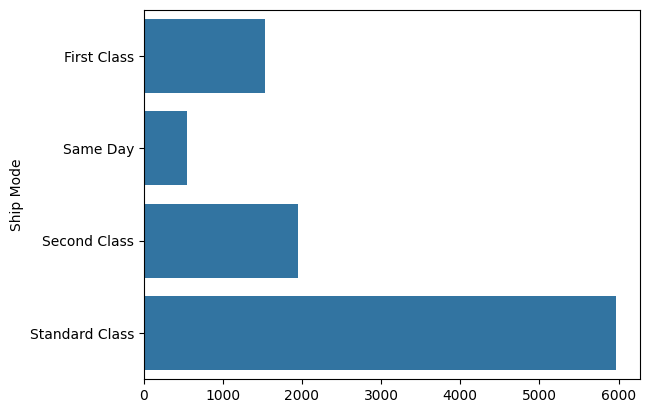

In [13]:
sns.barplot(x = ship.values, y = ship.index)
plt.show()

In [14]:
# NO 3

data["Total sales"] = data["Quantity"] * data["Sales"]

sales_region = data.groupby("Region")["Total sales"].sum()
sales_region

Region
Central    2.475833e+06
East       3.379326e+06
South      2.037675e+06
West       3.594741e+06
Name: Total sales, dtype: float64

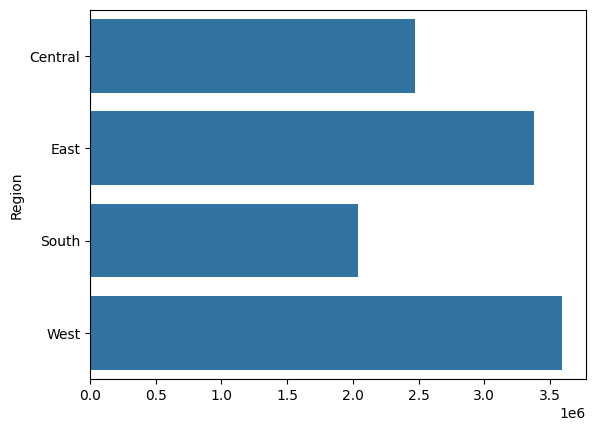

In [15]:
sns.barplot(x = sales_region.values, y = sales_region.index)
plt.show()

In [17]:
print(f"Penjualan tertinggi : {sales_region.idxmax()}")
print(f"Penjualan terendah : {sales_region.idxmin()}")

Penjualan tertinggi : West
Penjualan terendah : South


In [66]:
# NO 4 

sales_profit = data.groupby("Category")[["Sales", "Profit"]].sum()
sales_profit

,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,718803.8720,122417.8528
Technology,836154.0330,145454.9481


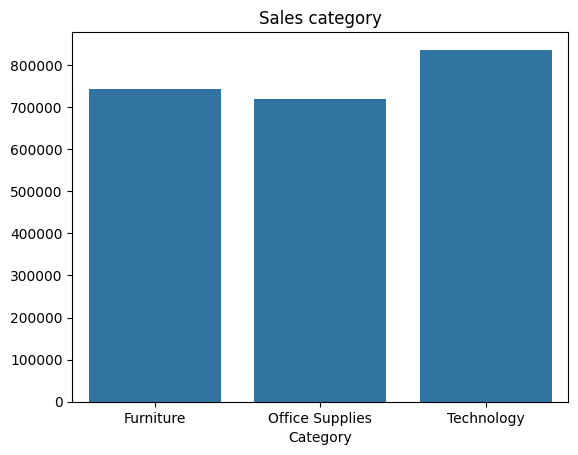

In [53]:
sns.barplot(x = sales_profit.index , y = sales_profit.values[0:,0])
plt.title("Sales category")
plt.show()

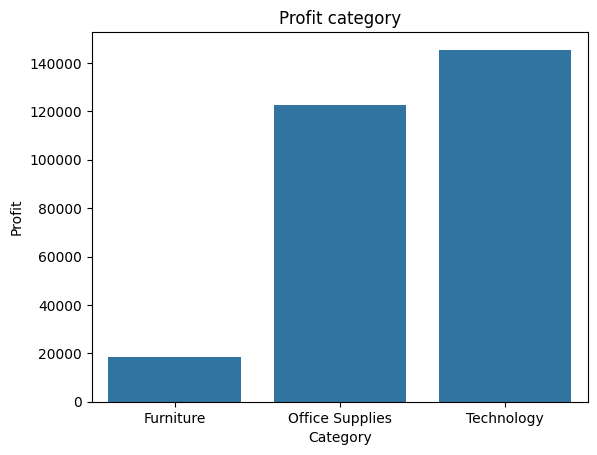

In [55]:
sns.barplot(x = sales_profit.index , y = sales_profit.values[0:,1])
plt.title("Profit category")
plt.ylabel("Profit")
plt.show()

In [56]:
# NO 5

data.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Total sales'],
      dtype='object')

In [57]:
discount = data.groupby("Discount")["Profit"].sum()
discount

Discount
0.00    320914.6552
0.10      9029.1770
0.15      1418.9915
0.20     90337.3060
0.30    -10369.2774
0.32     -2391.1377
0.40    -23057.0504
0.45     -2493.1111
0.50    -20506.4281
0.60     -5944.6552
0.70    -40075.3569
0.80    -30539.0392
Name: Profit, dtype: float64

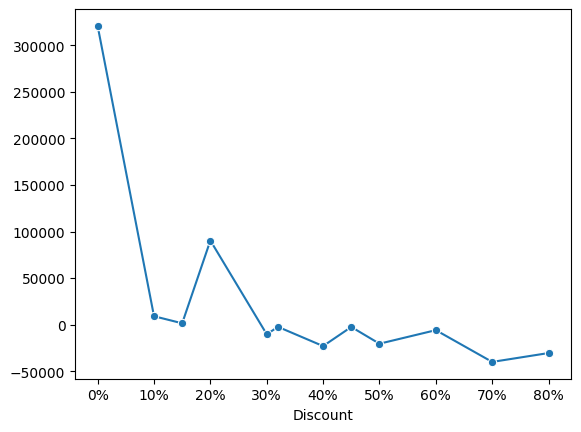

In [68]:
sns.lineplot(x=discount.index, y=discount.values, marker="o")
plt.xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], labels=["0%", "10%", "20%", "30%", "40%", "50%", "60%", "70%", "80%"])
plt.show()

FINAL PROJECT 1


In [69]:
data = pd.read_csv("data/dataset_final_project (2).csv")
data

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1


In [72]:
data.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Date', 'Time', 'Payment',
       'Rating'],
      dtype='object')

In [76]:
data["Product line"].unique()

array(['Health and beauty', 'Electronic accessories',
       'Home and lifestyle', 'Sports and travel', 'Food and beverages',
       'Fashion accessories'], dtype=object)

In [77]:
data["Payment"].unique()

array(['Ewallet', 'Cash', 'Credit card'], dtype=object)

In [78]:
# NO 1 

data["Branch"].replace({"A" : 1, 
                        "B" : 2, 
                        "C" : 3}, inplace=True)
data["City"].replace({"Yangon" : 1, 
                      "Naypyitaw" : 2, 
                      "Mandalay" : 3}, inplace=True)
data["Customer type"].replace({"Normal" : 1, 
                               "Member" : 2}, inplace=True)
data["Product line"].replace({"Electronic accessories" : 1, 
                              "Fashion accessories" : 2, 
                              "Food and beverages" : 3, 
                              "Health and beauty" : 4,
                              "Home and lifestyle" : 5,
                              "Sports and travel" : 6}, inplace=True)
data["Payment"].replace({"Cash" : 1, 
                        "Credit card" : 2, 
                        "Ewallet" : 3}, inplace=True)

data

C:\Users\agung\AppData\Local\Temp\ipykernel_103220\2582051962.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data["Product line"].replace({"Electronic accessories" : 1,
C:\Users\agung\AppData\Local\Temp\ipykernel_103220\2582051962.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data["Paym

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating
0,750-67-8428,1,1,2,Female,4,74.69,7,1/5/2019,13:08,3,9.1
1,226-31-3081,3,2,1,Female,1,15.28,5,3/8/2019,10:29,1,9.6
2,631-41-3108,1,1,1,Male,5,46.33,7,3/3/2019,13:23,2,7.4
3,123-19-1176,1,1,2,Male,4,58.22,8,1/27/2019,20:33,3,8.4
4,373-73-7910,1,1,1,Male,6,86.31,7,2/8/2019,10:37,3,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,3,2,1,Male,4,40.35,1,1/29/2019,13:46,3,6.2
996,303-96-2227,2,3,1,Female,5,97.38,10,3/2/2019,17:16,3,4.4
997,727-02-1313,1,1,2,Male,3,31.84,1,2/9/2019,13:22,1,7.7
998,347-56-2442,1,1,1,Male,5,65.82,1,2/22/2019,15:33,1,4.1


In [79]:
# NO 2

data["Total"] = data["Unit price"] * data["Quantity"]
data["Tax"] = data["Total"] * 0.05
data["Final price"] = data["Total"] - data["Tax"]

data

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating,Total,Tax,Final price
0,750-67-8428,1,1,2,Female,4,74.69,7,1/5/2019,13:08,3,9.1,522.83,26.1415,496.6885
1,226-31-3081,3,2,1,Female,1,15.28,5,3/8/2019,10:29,1,9.6,76.40,3.8200,72.5800
2,631-41-3108,1,1,1,Male,5,46.33,7,3/3/2019,13:23,2,7.4,324.31,16.2155,308.0945
3,123-19-1176,1,1,2,Male,4,58.22,8,1/27/2019,20:33,3,8.4,465.76,23.2880,442.4720
4,373-73-7910,1,1,1,Male,6,86.31,7,2/8/2019,10:37,3,5.3,604.17,30.2085,573.9615
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,3,2,1,Male,4,40.35,1,1/29/2019,13:46,3,6.2,40.35,2.0175,38.3325
996,303-96-2227,2,3,1,Female,5,97.38,10,3/2/2019,17:16,3,4.4,973.80,48.6900,925.1100
997,727-02-1313,1,1,2,Male,3,31.84,1,2/9/2019,13:22,1,7.7,31.84,1.5920,30.2480
998,347-56-2442,1,1,1,Male,5,65.82,1,2/22/2019,15:33,1,4.1,65.82,3.2910,62.5290


In [81]:
# NO 3

data.isnull().sum()

Invoice ID       0
Branch           0
City             0
Customer type    0
Gender           0
Product line     0
Unit price       0
Quantity         0
Date             0
Time             0
Payment          0
Rating           0
Total            0
Tax              0
Final price      0
dtype: int64

In [82]:
data.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Date', 'Time', 'Payment',
       'Rating', 'Total', 'Tax', 'Final price'],
      dtype='object')

In [83]:
# NO 4 A

produk = data.groupby("Product line")["Quantity"].sum()
produk

Product line
1    971
2    902
3    952
4    854
5    911
6    920
Name: Quantity, dtype: int64

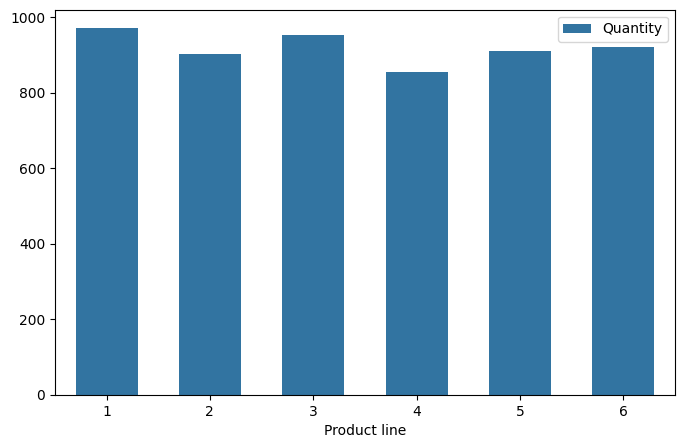

In [96]:
plt.figure(figsize=(8,5))
sns.barplot(x = produk.index, y = produk.values, label = "Quantity", width = 0.6)
plt.legend()
plt.show()

In [107]:
# NO 4 B

normal = data.loc[data["Customer type"] == 1]
normal_group = normal.groupby("Product line")["Customer type"].count()
normal_group

Product line
1    92
2    92
3    80
4    79
5    77
6    79
Name: Customer type, dtype: int64

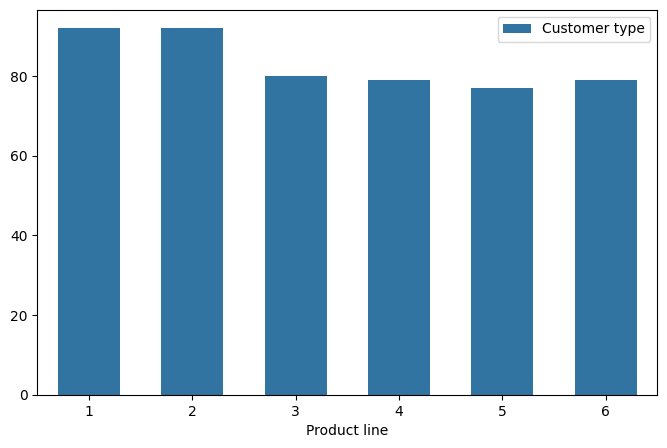

In [108]:
plt.figure(figsize=(8,5))
sns.barplot(x = normal_group.index, y = normal_group.values, label = "Customer type", width = 0.6)
plt.legend()
plt.show()

In [109]:
member = data.loc[data["Customer type"] == 2]
member_group = member.groupby("Product line")["Customer type"].count()
member_group

Product line
1    78
2    86
3    94
4    73
5    83
6    87
Name: Customer type, dtype: int64

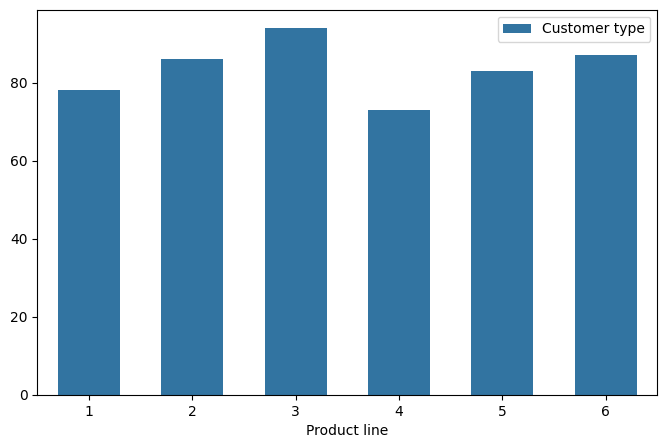

In [110]:
plt.figure(figsize=(8,5))
sns.barplot(x = member_group.index, y = member_group.values, label = "Customer type", width = 0.6)
plt.legend()
plt.show()

In [111]:
# NO 4 C

payment = data.groupby("Payment")["Invoice ID"].count()
payment

Payment
1    344
2    311
3    345
Name: Invoice ID, dtype: int64

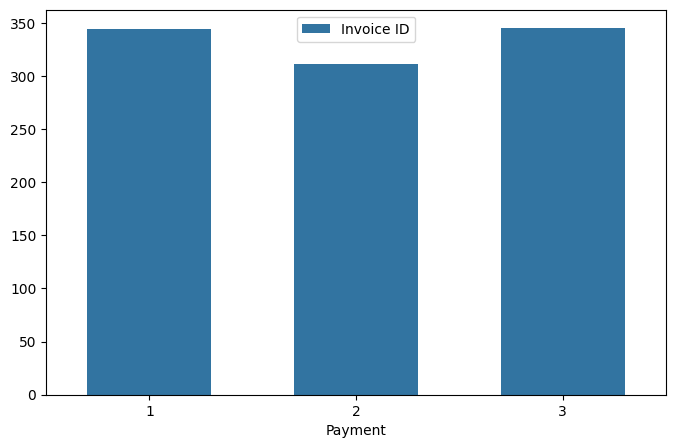

In [112]:
plt.figure(figsize=(8,5))
sns.barplot(x = payment.index, y = payment.values, label = "Invoice ID", width = 0.6)
plt.legend()
plt.show()

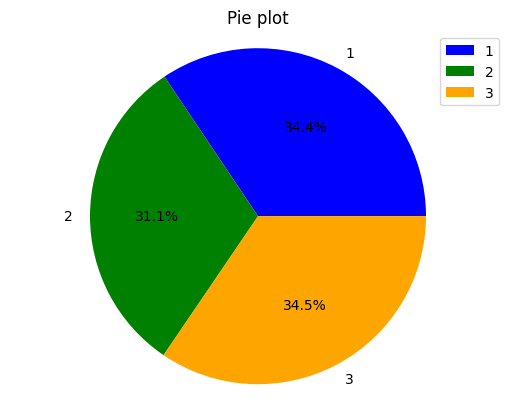

In [120]:
# NO 4 D

plt.pie(payment.values, labels = payment.index, autopct='%1.1f%%', colors=['blue', 'green', 'orange'])
plt.title('Pie plot')
plt.axis('equal')
plt.legend()
plt.show()

In [117]:
# NO 4 E

profit = data.groupby("Product line")["Final price"].sum()
profit

Product line
1    49162.5285
2    49133.9050
3    50797.7160
4    44508.6210
5    48732.2070
6    49873.0335
Name: Final price, dtype: float64

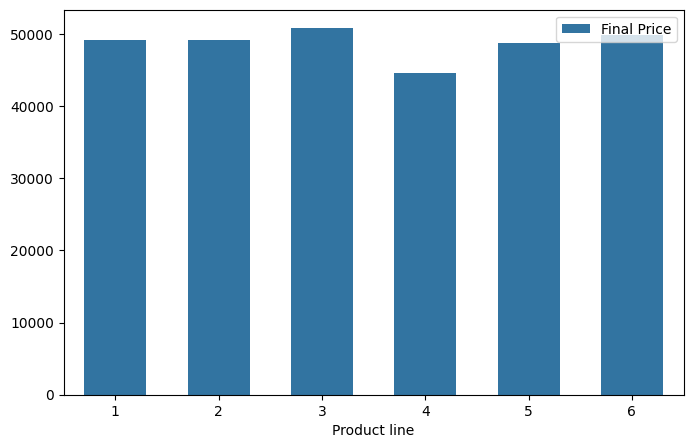

In [118]:
plt.figure(figsize=(8,5))
sns.barplot(x = profit.index, y = profit.values, label = "Final Price", width = 0.6)
plt.legend()
plt.show()